# Reto 2: Transformer autoregresivo para el modelo de Ising 2D

Este notebook contiene el código y los resultados numéricos del documento `sol_Reto2_FCC.pdf`, que está en esta misma carpeta. Se implementa el algoritmo de la sección C del enunciado: un Transformer autoregresivo $q_\theta(s)$ que se entrena minimizando la energía libre variacional $F[q_\theta]=\langle E\rangle_{q_\theta}-TS[q_\theta]$ del modelo de Ising en una red cuadrada $L\times L$ con condiciones periódicas, $J=1$, $h=0$ y $k_B=1$.

Las figuras se guardan en `figuras_reto2/` y los valores que se citan en el documento, en `figuras_reto2/resultados.json`. Todo corre en CPU; la ejecución completa tarda unos 70 minutos con 8 hilos.

In [1]:
import itertools, copy, json, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(8)
FIG = Path("figuras_reto2")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 10})
TC = 2 / np.log(1 + np.sqrt(2))
res = {}   # valores que se citan en el documento
t_inicio = time.time()
print(f"torch {torch.__version__}, hilos: {torch.get_num_threads()}, Tc = {TC:.4f}")

torch 2.14.0+cu130, hilos: 8, Tc = 2.2692


## 1. Energía de Ising

Los sitios se recorren por filas, de modo que el sitio $(x,y)$ ocupa la posición $i=yL+x$ de la secuencia. Con `torch.roll` se obtienen el vecino de la derecha y el de abajo con fronteras periódicas, y así cada enlace se cuenta una sola vez. Como prueba, los dos estados ferromagnéticos deben dar $E=-2N$ y la configuración ajedrezada ($L$ par) $E=+2N$.

In [2]:
def energia_ising(s, L, J=1.0, h=0.0):
    # s: tensor (M, N) con valores +-1, ordenado por filas
    g = s.reshape(-1, L, L)
    der = torch.roll(g, shifts=-1, dims=2)
    aba = torch.roll(g, shifts=-1, dims=1)
    return -J * (g * (der + aba)).sum(dim=(1, 2)) - h * g.sum(dim=(1, 2))

L = 4; N = L * L
x, y = np.meshgrid(range(L), range(L))
ajedrez = torch.tensor(1 - 2 * ((x + y) % 2), dtype=torch.float32).reshape(1, N)
prueba_E = [energia_ising(torch.ones(1, N), L).item(),
            energia_ising(-torch.ones(1, N), L).item(),
            energia_ising(ajedrez, L).item()]
print("E(+), E(-), E(ajedrez) =", prueba_E, "  esperado:", [-2 * N, -2 * N, 2 * N])

E(+), E(-), E(ajedrez) = [-32.0, -32.0, 32.0]   esperado: [-32, -32, 32]


## 2. Transformer autoregresivo

Los tokens son 0 para $s_i=-1$, 1 para $s_i=+1$ y 2 para `BOS`. La entrada es la secuencia desplazada $(\mathtt{BOS},s_1,\dots,s_{N-1})$ y la salida en la posición $i$ da los dos logits de $s_i$. A cada token se le suma un embedding de posición aprendido. Cada bloque tiene atención multi-cabeza con máscara causal y un MLP, con LayerNorm antes de cada subcapa y conexiones residuales, y no hay dropout.

En el muestreo se guardan las claves y los valores de las posiciones ya generadas (caché KV), de modo que cada paso procesa solo el token nuevo. La consulta de la posición $i$ ve entonces las posiciones $0,\dots,i$, que es exactamente lo que permite la máscara causal en la evaluación completa. El muestreo devuelve también $\ln q_\theta(s)$ acumulado, que sirve para comprobar que ambas rutas calculan la misma distribución.

In [3]:
BOS = 2

class Bloque(nn.Module):
    def __init__(self, d, n_cabezas):
        super().__init__()
        self.h = n_cabezas
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d)
        self.proy = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mascara=None, cache=None):
        M, n, d = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(d, dim=-1)
        q, k, v = (t.view(M, n, self.h, d // self.h).transpose(1, 2) for t in (q, k, v))
        if cache is not None:              # muestreo: se agregan las claves previas
            if "k" in cache:
                k = torch.cat([cache["k"], k], dim=2)
                v = torch.cat([cache["v"], v], dim=2)
            cache["k"], cache["v"] = k, v
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=mascara)
        x = x + self.proy(a.transpose(1, 2).reshape(M, n, d))
        return x + self.mlp(self.ln2(x))


class TransformerEspines(nn.Module):
    def __init__(self, N, d=32, n_cabezas=4, n_capas=2):
        super().__init__()
        self.N = N
        self.tok = nn.Embedding(3, d)          # 0: -1, 1: +1, 2: BOS
        self.pos = nn.Embedding(N, d)
        self.bloques = nn.ModuleList([Bloque(d, n_cabezas) for _ in range(n_capas)])
        self.ln = nn.LayerNorm(d)
        self.salida = nn.Linear(d, 2)          # W_out h_i + b
        self.register_buffer("mascara", torch.ones(N, N, dtype=torch.bool).tril())

    def logits(self, tokens):                  # tokens: (M, n)
        n = tokens.shape[1]
        x = self.tok(tokens) + self.pos.weight[:n]
        for b in self.bloques:
            x = b(x, mascara=self.mascara[:n, :n])
        return self.salida(self.ln(x))         # (M, n, 2)

    def log_condicionales(self, s):            # ln q(s_i | s_<i), forma (M, N)
        idx = ((s + 1) / 2).long()
        ent = torch.cat([torch.full_like(idx[:, :1], BOS), idx[:, :-1]], dim=1)
        logp = F.log_softmax(self.logits(ent), dim=-1)
        return logp.gather(-1, idx.unsqueeze(-1)).squeeze(-1)

    def log_prob(self, s):
        return self.log_condicionales(s).sum(dim=1)

    @torch.no_grad()
    def muestrear(self, M, con_logq=True):
        tok = torch.full((M, 1), BOS, dtype=torch.long)
        caches = [dict() for _ in self.bloques]
        logq = torch.zeros(M, dtype=self.salida.weight.dtype)
        espines = []
        for i in range(self.N):
            x = self.tok(tok) + self.pos.weight[i]
            for b, c in zip(self.bloques, caches):
                x = b(x, cache=c)
            logp = F.log_softmax(self.salida(self.ln(x[:, -1])), dim=-1)
            tok = torch.multinomial(logp.exp(), 1)
            logq += logp.gather(1, tok).squeeze(1)
            espines.append(tok)
        s = 2 * torch.cat(espines, dim=1) - 1
        return s.to(logq.dtype), logq


n_par = sum(p.numel() for p in TransformerEspines(16).parameters())
print("parámetros para N = 16:", n_par)
res["n_parametros"] = {L_: sum(p.numel() for p in TransformerEspines(L_ * L_).parameters()) for L_ in (3, 4, 8)}
print(res["n_parametros"])

parámetros para N = 16: 26146
{3: 25922, 4: 26146, 8: 27682}


## 3. Valores exactos

Para $L\le 4$ se enumeran las $2^N$ configuraciones y se calculan $Z$, $F_B=-T\ln Z$, $U_B$, $S_B$ y $\langle|m|\rangle_B$. Evaluando el modelo sobre todas las configuraciones se obtienen también los valores exactos de $\sum_s q_\theta(s)$, $F_\theta$ y $D_{KL}(q_\theta\|p_B)$. Esta evaluación se hace en doble precisión sobre una copia del modelo.

Para $L=8$ la enumeración no es viable, pero la función de partición de una red finita con fronteras periódicas tiene forma cerrada (Kaufman, 1949):
$$Z=\tfrac12\,(2\sinh 2K)^{N/2}\sum_{j=1}^{4}Z_j,\qquad K=J/T,$$
con $Z_1=\prod_{r=0}^{L-1}2\cosh(L\gamma_{2r+1}/2)$, $Z_2$ igual con $\sinh$, y $Z_3$, $Z_4$ igual con los índices pares $\gamma_{2r}$. Aquí $\cosh\gamma_k=\cosh 2K\coth 2K-\cos(\pi k/L)$ y $\gamma_0=2K+\ln\tanh K$. La energía media se obtiene derivando numéricamente, $U=-\partial\ln Z/\partial\beta$. La fórmula se compara con la enumeración para $L=2,3,4$.

In [4]:
def enumeracion_exacta(L, T):
    N = L * L
    s = torch.tensor(list(itertools.product([-1, 1], repeat=N)), dtype=torch.float64)
    E = energia_ising(s, L)
    logZ = torch.logsumexp(-E / T, dim=0)
    logpB = -E / T - logZ
    pB = logpB.exp()
    return dict(s=s, E=E, logpB=logpB, logZ=logZ.item(), FB=-T * logZ.item(),
                UB=(pB * E).sum().item(), SB=-(pB * logpB).sum().item(),
                mB=(pB * s.mean(1).abs()).sum().item())


@torch.no_grad()
def evaluacion_exacta(modelo, ex, T, bloque=8192):
    m64 = copy.deepcopy(modelo).double()
    logq = torch.cat([m64.log_prob(ex["s"][i:i + bloque]) for i in range(0, len(ex["s"]), bloque)])
    q = logq.exp()
    F_t = (q * (ex["E"] + T * logq)).sum().item()
    return dict(norma=q.sum().item(), F=F_t, U=(q * ex["E"]).sum().item(),
                S=-(q * logq).sum().item(), m=(q * ex["s"].mean(1).abs()).sum().item(),
                DKL=(q * (logq - ex["logpB"])).sum().item(), DKL_F=(F_t - ex["FB"]) / T, logq=logq)


def logZ_kaufman(L, T, J=1.0):
    K = J / T
    k = np.arange(2 * L)
    g = np.arccosh(np.cosh(2 * K) / np.tanh(2 * K) - np.cos(np.pi * k / L))
    g[0] = 2 * K + np.log(np.tanh(K))
    terminos = [2 * fun(L * gk / 2) for gk in (g[1::2], g[0::2]) for fun in (np.cosh, np.sinh)]
    logs = np.array([np.log(np.abs(t)).sum() for t in terminos])
    signos = np.array([np.prod(np.sign(t)) for t in terminos])
    lmax = logs.max()
    return np.log(0.5) + L * L / 2 * np.log(2 * np.sinh(2 * K)) + lmax + np.log((signos * np.exp(logs - lmax)).sum())


def U_kaufman(L, T, db=1e-5):
    b = 1 / T
    return -(logZ_kaufman(L, 1 / (b + db)) - logZ_kaufman(L, 1 / (b - db))) / (2 * db)


for L in (2, 3, 4):
    for T in (1.0, 2.269, 4.0):
        ex = enumeracion_exacta(L, T)
        print(f"L={L} T={T}: ln Z exacto = {ex['logZ']:.10f}, Kaufman = {logZ_kaufman(L, T):.10f};"
              f"  U exacto = {ex['UB']:.6f}, Kaufman = {U_kaufman(L, T):.6f}")

L=2 T=1.0: ln Z exacto = 8.6951580457, Kaufman = 8.6951580457;  U exacto = -7.983928, Kaufman = -7.983928
L=2 T=2.269: ln Z exacto = 4.3822709609, Kaufman = 4.3822709609;  U exacto = -6.788525, Kaufman = -6.788525
L=2 T=4.0: ln Z exacto = 3.2976420048, Kaufman = 3.2976420048;  U exacto = -4.290749, Kaufman = -4.290749
L=3 T=1.0: ln Z exacto = 18.6963200577, Kaufman = 18.6963200577;  U exacto = -17.973979, Kaufman = -17.973979
L=3 T=2.269: ln Z exacto = 9.0207353456, Kaufman = 9.0207353456;  U exacto = -14.502266, Kaufman = -14.502266
L=3 T=4.0: ln Z exacto = 6.9574847468, Kaufman = 6.9574847468;  U exacto = -6.723062, Kaufman = -6.723062
L=4 T=1.0: ln Z exacto = 32.6987214019, Kaufman = 32.6987214019;  U exacto = -31.954535, Kaufman = -31.954535


L=4 T=2.269: ln Z exacto = 15.5228170959, Kaufman = 15.5228170959;  U exacto = -25.052303, Kaufman = -25.052303


L=4 T=4.0: ln Z exacto = 12.2012710249, Kaufman = 12.2012710249;  U exacto = -10.007778, Kaufman = -10.007778


## 4. Pruebas de la implementación

Con modelos sin entrenar ($L=3$ y $L=4$, $T=2.269$) se verifica:

1. la normalización $\sum_s q_\theta(s)=1$;
2. la causalidad: al cambiar $s_k$ no deben cambiar las condicionales $q_\theta(s_i\mid s_{<i})$ con $i<k$;
3. que el $\ln q_\theta(s)$ acumulado durante el muestreo coincide con el de la evaluación en una pasada;
4. que $D_{KL}(q_\theta\|p_B)$ calculada directamente coincide con $(F_\theta-F_B)/T$.

In [5]:
T0 = 2.269
res["pruebas"] = {}
for L in (3, 4):
    N = L * L
    torch.manual_seed(0)
    modelo = TransformerEspines(N)
    ex = enumeracion_exacta(L, T0)
    r = evaluacion_exacta(modelo, ex, T0)
    s, logq_muestreo = modelo.muestrear(2000)
    with torch.no_grad():
        consistencia = (modelo.log_prob(s) - logq_muestreo).abs().max().item()
        base = modelo.log_condicionales(s[:200])
        viol, cambio = 0.0, 0.0
        for k in range(N):
            s2 = s[:200].clone()
            s2[:, k] *= -1
            d = (modelo.log_condicionales(s2) - base).abs()
            if k > 0:
                viol = max(viol, d[:, :k].max().item())
            if k < N - 1:
                cambio = max(cambio, d[:, k + 1:].max().item())
    res["pruebas"][L] = dict(norma_menos_1=r["norma"] - 1, causalidad=viol, cambio_posteriores=cambio,
                             consistencia=consistencia, DKL=r["DKL"], DKL_F=r["DKL_F"])
    print(f"L={L}: |sum q - 1| = {abs(r['norma'] - 1):.1e}, violación causal = {viol:.1e} "
          f"(cambio en posiciones posteriores {cambio:.2f}), |ln q muestreo - ln q eval| = {consistencia:.1e}, "
          f"D_KL = {r['DKL']:.6f}, (F-FB)/T = {r['DKL_F']:.6f}")

L=3: |sum q - 1| = 2.2e-16, violación causal = 0.0e+00 (cambio en posiciones posteriores 1.00), |ln q muestreo - ln q eval| = 1.4e-06, D_KL = 3.076495, (F-FB)/T = 3.076495


L=4: |sum q - 1| = 0.0e+00, violación causal = 0.0e+00 (cambio en posiciones posteriores 0.53), |ln q muestreo - ln q eval| = 2.9e-06, D_KL = 4.198104, (F-FB)/T = 4.198104


## 5. Entrenamiento

Cada iteración genera un lote nuevo con los parámetros actuales, sin grafo de diferenciación, calcula $E_m$ y evalúa $l_m=\ln q_\theta(s^{(m)})$ con gradiente. La función auxiliar es
$$\mathcal{L}_{aux}=\frac1M\sum_{m=1}^{M}\mathrm{stopgrad}(f_m-b)\,l_m .$$
Con `linea_base=False` se tiene $b=0$, que es el algoritmo del enunciado. Con `linea_base=True` se usa $b=\bar f$, la media del lote, que en valor esperado solo multiplica el gradiente por $(1-1/M)$ y reduce mucho su varianza (ver la sección 7). En cada iteración se registran $\hat F_\theta$, $\hat U_\theta$, $\hat S_\theta$ y la varianza de $f_m$, y cada `cada` iteraciones, si hay enumeración, la $D_{KL}$ exacta.

In [6]:
def entrenar(modelo, L, T, M=512, K=2000, lr=1e-3, linea_base=True, ex=None, cada=25, semilla=0, K_rec=0):
    # K_rec > 0: recocido, beta crece linealmente de beta/K_rec a beta en K_rec iteraciones
    torch.manual_seed(semilla)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    h = dict(F=[], U=[], S=[], varf=[], T=[], it_dkl=[], dkl=[])
    t0 = time.time()
    for t in range(K):
        T_t = T / min(1.0, (t + 1) / K_rec) if K_rec > 0 else T
        s, _ = modelo.muestrear(M, con_logq=False) # sin grafo
        E = energia_ising(s, L)
        l = modelo.log_prob(s)                     # con grafo
        f = (E + T_t * l).detach()                 # stopgrad(f)
        peso = f - f.mean() if linea_base else f
        perdida = (peso * l).mean()                # L_aux
        opt.zero_grad()
        perdida.backward()
        opt.step()
        h["F"].append(f.mean().item()); h["U"].append(E.mean().item())
        h["S"].append(-l.mean().item()); h["varf"].append(f.var().item()); h["T"].append(T_t)
        if ex is not None and (t % cada == 0 or t == K - 1):
            h["it_dkl"].append(t); h["dkl"].append(evaluacion_exacta(modelo, ex, T)["DKL"])
    h["tiempo"] = time.time() - t0
    return {k: np.array(v) if isinstance(v, list) else v for k, v in h.items()}


@torch.no_grad()
def evaluar_lote(modelo, L, T, M=20000, bloque=5000):
    # lote independiente de evaluacion: medias por espin y su error estandar
    N = L * L
    partes = [modelo.muestrear(min(bloque, M - i)) for i in range(0, M, bloque)]
    s = torch.cat([p[0] for p in partes]); l = torch.cat([p[1] for p in partes])
    E = energia_ising(s, L); f = E + T * l; mag = s.mean(1)
    ee = lambda a: (a.mean().item(), a.std().item() / np.sqrt(len(a)))
    no_nulo = mag != 0
    logZ_is = (torch.logsumexp(-f.double() / T, 0) - np.log(M)).item()   # Z = <exp(-f/T)>_q
    w = torch.exp(-(f.double() - f.min()) / T)
    return dict(F=ee(f / N), U=ee(E / N), S=ee(-l / N), m=ee(mag.abs()),
                frac_pos=(mag[no_nulo] > 0).float().mean().item(),
                FB_is=-T * logZ_is / N, ess=(w.sum() ** 2 / (w ** 2).sum()).item() / M, s=s)

## 6. Validación con $L=3$ y $L=4$ a $T=2.269$

Se usa $d=32$, 4 cabezas, 2 bloques, $M=512$, Adam con $\eta=10^{-3}$ y $K=2000$ iteraciones. Para $L=4$ se entrena también con $b=0$ para comparar. Al final se genera un lote independiente de $20\,000$ configuraciones.

In [7]:
T0 = 2.269
HP = dict(d=32, n_cabezas=4, n_capas=2, M=512, lr=1e-3, K=2000, semilla=0)
res["hiperparametros"] = HP
modelos, hist, exactos, eval_ex, eval_lote = {}, {}, {}, {}, {}
for clave, L, lb in [("L3", 3, True), ("L4", 4, True), ("L4_sin_b", 4, False)]:
    N = L * L
    ex = exactos.setdefault(L, enumeracion_exacta(L, T0))
    torch.manual_seed(HP["semilla"])
    modelos[clave] = TransformerEspines(N, HP["d"], HP["n_cabezas"], HP["n_capas"])
    hist[clave] = entrenar(modelos[clave], L, T0, M=HP["M"], K=HP["K"], lr=HP["lr"],
                           linea_base=lb, ex=ex, semilla=HP["semilla"])
    eval_ex[clave] = evaluacion_exacta(modelos[clave], ex, T0)
    torch.manual_seed(123)
    eval_lote[clave] = evaluar_lote(modelos[clave], L, T0)
    print(f"{clave}: {hist[clave]['tiempo']:.0f} s, D_KL final = {eval_ex[clave]['DKL']:.2e}")

L3: 43 s, D_KL final = 1.61e-04


L4: 354 s, D_KL final = 8.42e-04


L4_sin_b: 372 s, D_KL final = 1.43e-01


In [8]:
res["validacion"] = {}
for clave, r in eval_ex.items():
    L = int(clave[1]); N = L * L; ex = exactos[L]; lo = eval_lote[clave]; h = hist[clave]
    res["validacion"][clave] = dict(
        F_lote=lo["F"], U_lote=lo["U"], S_lote=lo["S"], m_lote=lo["m"], frac_pos=lo["frac_pos"],
        F_exacta=r["F"] / N, U_exacta=r["U"] / N, S_exacta=r["S"] / N, m_exacta=r["m"],
        FB=ex["FB"] / N, UB=ex["UB"] / N, SB=ex["SB"] / N, mB=ex["mB"],
        norma_menos_1=r["norma"] - 1, DKL=r["DKL"], DKL_F=r["DKL_F"],
        frac_F_bajo_FB_ultimas500=float((h["F"][-500:] < ex["FB"]).mean()),
        varf_inicial=float(h["varf"][:10].mean()), varf_final=float(h["varf"][-100:].mean()),
        tiempo=h["tiempo"])
    v = res["validacion"][clave]
    print(f"{clave}: F/N lote = {v['F_lote'][0]:.5f} ± {v['F_lote'][1]:.5f}, exacta del modelo = {v['F_exacta']:.5f}, "
          f"FB/N = {v['FB']:.5f}")
    print(f"      U/N lote = {v['U_lote'][0]:.4f} ± {v['U_lote'][1]:.4f}, UB/N = {v['UB']:.4f};  "
          f"<|m|> lote = {v['m_lote'][0]:.4f} ± {v['m_lote'][1]:.4f}, mB = {v['mB']:.4f}")
    print(f"      sum q - 1 = {v['norma_menos_1']:.1e}, D_KL = {v['DKL']:.3e}, (F-FB)/T = {v['DKL_F']:.3e}, "
          f"fracción m>0 = {v['frac_pos']:.3f}, var f: {v['varf_inicial']:.2f} -> {v['varf_final']:.3f}")

L3: F/N lote = -2.27421 ± 0.00003, exacta del modelo = -2.27419, FB/N = -2.27423
      U/N lote = -1.6068 ± 0.0043, UB/N = -1.6114;  <|m|> lote = 0.8696 ± 0.0016, mB = 0.8711
      sum q - 1 = -1.1e-16, D_KL = 1.606e-04, (F-FB)/T = 1.606e-04, fracción m>0 = 0.500, var f: 8.78 -> 0.002
L4: F/N lote = -2.20121 ± 0.00004, exacta del modelo = -2.20121, FB/N = -2.20133
      U/N lote = -1.5626 ± 0.0036, UB/N = -1.5658;  <|m|> lote = 0.8433 ± 0.0016, mB = 0.8439
      sum q - 1 = 0.0e+00, D_KL = 8.419e-04, (F-FB)/T = 8.419e-04, fracción m>0 = 0.498, var f: 29.39 -> 0.010
L4_sin_b: F/N lote = -2.18054 ± 0.00047, exacta del modelo = -2.18109, FB/N = -2.20133
      U/N lote = -1.6292 ± 0.0033, UB/N = -1.5658;  <|m|> lote = 0.8892 ± 0.0012, mB = 0.8439
      sum q - 1 = 0.0e+00, D_KL = 1.427e-01, (F-FB)/T = 1.427e-01, fracción m>0 = 0.526, var f: 34.30 -> 1.326


### Curvas de entrenamiento y $D_{KL}$ exacta

Las curvas muestran los estimadores de lote en cada iteración (en gris) y su media móvil de 50 iteraciones, junto con los valores exactos de Boltzmann.

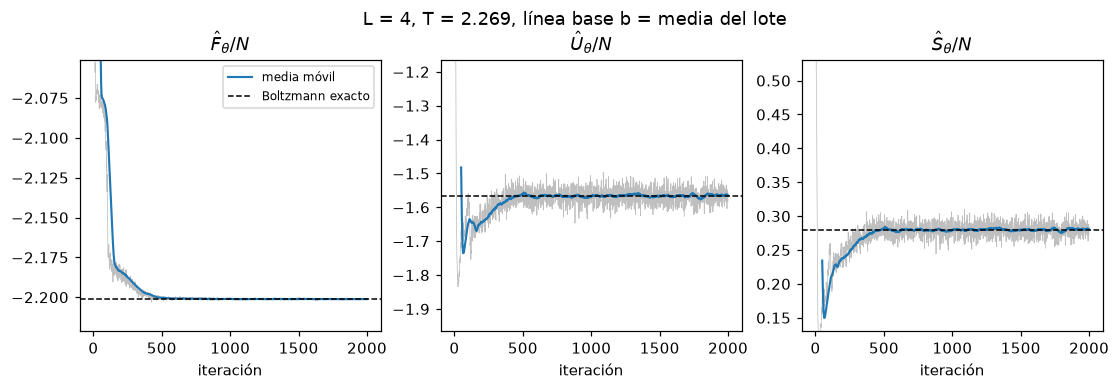

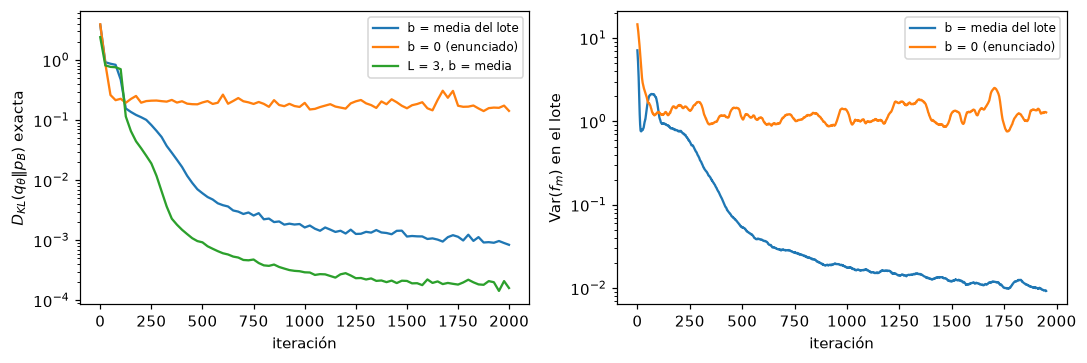

In [9]:
def media_movil(a, w=50):
    return np.convolve(a, np.ones(w) / w, mode="valid")

L, N, ex = 4, 16, exactos[4]
h = hist["L4"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, k, ref, nombre in zip(ax, ("F", "U", "S"), (ex["FB"], ex["UB"], ex["SB"]),
                             (r"$\hat F_\theta/N$", r"$\hat U_\theta/N$", r"$\hat S_\theta/N$")):
    it = np.arange(len(h[k]))
    a.plot(it, h[k] / N, color="0.75", lw=0.5)
    a.plot(it[49:], media_movil(h[k] / N), color="C0", lw=1.4, label="media móvil")
    a.axhline(ref / N, color="k", ls="--", lw=1, label="Boltzmann exacto")
    a.set_xlabel("iteración"); a.set_title(nombre)
ax[0].set_ylim(ex["FB"] / N - 0.02, ex["FB"] / N + 0.15)
ax[1].set_ylim(ex["UB"] / N - 0.4, ex["UB"] / N + 0.4)
ax[2].set_ylim(ex["SB"] / N - 0.15, ex["SB"] / N + 0.25)
ax[0].legend(fontsize=8)
fig.suptitle(f"L = 4, T = {T0}, línea base b = media del lote", y=1.02)
fig.savefig(FIG / "curvas_entrenamiento_L4.pdf"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for clave, et in (("L4", "b = media del lote"), ("L4_sin_b", "b = 0 (enunciado)"), ("L3", "L = 3, b = media")):
    ax[0].semilogy(hist[clave]["it_dkl"], hist[clave]["dkl"], label=et)
ax[0].set_xlabel("iteración"); ax[0].set_ylabel(r"$D_{KL}(q_\theta\|p_B)$ exacta"); ax[0].legend(fontsize=8)
for clave, et in (("L4", "b = media del lote"), ("L4_sin_b", "b = 0 (enunciado)")):
    ax[1].semilogy(media_movil(hist[clave]["varf"]), label=et)
ax[1].set_xlabel("iteración"); ax[1].set_ylabel(r"Var$(f_m)$ en el lote"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "dkl_vs_iter_L4.pdf"); plt.show()

### Colapso transitorio al inicio del entrenamiento

En la curva de $D_{KL}$ con línea base aparece, durante las primeras cien iteraciones, una meseta algo por encima de $\ln 2\approx0.69$. Para ver de dónde sale se repiten las primeras 160 iteraciones de las mismas corridas (misma semilla y mismo algoritmo) y cada 10 iteraciones se calcula la masa exacta que el modelo asigna a cada sector de magnetización.

In [10]:
# Se repiten las primeras 160 iteraciones de la validacion (misma semilla, linea base)
# y cada 10 iteraciones se mide la masa exacta que q asigna a cada sector.
res["meseta"] = {}
for L in (3, 4):
    N = L * L
    ex = enumeracion_exacta(L, T0)
    mag = ex["s"].mean(1)
    torch.manual_seed(HP["semilla"])
    mod = TransformerEspines(N, HP["d"], HP["n_cabezas"], HP["n_capas"])
    torch.manual_seed(HP["semilla"])
    opt = torch.optim.Adam(mod.parameters(), lr=HP["lr"])
    filas = []
    for t in range(160):
        s, _ = mod.muestrear(HP["M"], con_logq=False)
        E = energia_ising(s, L)
        l = mod.log_prob(s)
        f = (E + T0 * l).detach()
        perdida = ((f - f.mean()) * l).mean()
        opt.zero_grad(); perdida.backward(); opt.step()
        if t % 10 == 0:
            r = evaluacion_exacta(mod, ex, T0)
            q = r["logq"].exp()
            filas.append(dict(it=t, DKL=r["DKL"], q_pos=q[mag > 0].sum().item(), q_neg=q[mag < 0].sum().item()))
    res["meseta"][L] = filas
    print(f"L = {L}")
    for fi in filas:
        print(f"  it {fi['it']:3d}: D_KL = {fi['DKL']:.3f}, q(m>0) = {fi['q_pos']:.3f}, q(m<0) = {fi['q_neg']:.3f}")

L = 3
  it   0: D_KL = 2.408, q(m>0) = 0.036, q(m<0) = 0.964
  it  10: D_KL = 0.787, q(m>0) = 0.000, q(m<0) = 1.000
  it  20: D_KL = 0.821, q(m>0) = 0.000, q(m<0) = 1.000
  it  30: D_KL = 0.802, q(m>0) = 0.000, q(m<0) = 1.000
  it  40: D_KL = 0.778, q(m>0) = 0.001, q(m<0) = 0.999
  it  50: D_KL = 0.771, q(m>0) = 0.001, q(m<0) = 0.999
  it  60: D_KL = 0.767, q(m>0) = 0.001, q(m<0) = 0.999
  it  70: D_KL = 0.763, q(m>0) = 0.002, q(m<0) = 0.998
  it  80: D_KL = 0.756, q(m>0) = 0.003, q(m<0) = 0.997
  it  90: D_KL = 0.746, q(m>0) = 0.006, q(m<0) = 0.994
  it 100: D_KL = 0.706, q(m>0) = 0.026, q(m<0) = 0.974
  it 110: D_KL = 0.285, q(m>0) = 0.353, q(m<0) = 0.647
  it 120: D_KL = 0.116, q(m>0) = 0.414, q(m<0) = 0.586
  it 130: D_KL = 0.098, q(m>0) = 0.473, q(m<0) = 0.527
  it 140: D_KL = 0.074, q(m>0) = 0.535, q(m<0) = 0.465
  it 150: D_KL = 0.066, q(m>0) = 0.495, q(m<0) = 0.505


L = 4
  it   0: D_KL = 3.876, q(m>0) = 0.336, q(m<0) = 0.515
  it  10: D_KL = 1.226, q(m>0) = 0.036, q(m<0) = 0.950
  it  20: D_KL = 0.901, q(m>0) = 0.000, q(m<0) = 1.000
  it  30: D_KL = 0.919, q(m>0) = 0.000, q(m<0) = 1.000
  it  40: D_KL = 0.887, q(m>0) = 0.000, q(m<0) = 1.000
  it  50: D_KL = 0.870, q(m>0) = 0.000, q(m<0) = 1.000
  it  60: D_KL = 0.852, q(m>0) = 0.001, q(m<0) = 0.998
  it  70: D_KL = 0.841, q(m>0) = 0.004, q(m<0) = 0.995
  it  80: D_KL = 0.822, q(m>0) = 0.009, q(m<0) = 0.989
  it  90: D_KL = 0.715, q(m>0) = 0.049, q(m<0) = 0.947
  it 100: D_KL = 0.474, q(m>0) = 0.170, q(m<0) = 0.826
  it 110: D_KL = 0.218, q(m>0) = 0.645, q(m<0) = 0.354
  it 120: D_KL = 0.173, q(m>0) = 0.436, q(m<0) = 0.563
  it 130: D_KL = 0.149, q(m>0) = 0.519, q(m<0) = 0.480
  it 140: D_KL = 0.141, q(m>0) = 0.504, q(m<0) = 0.494
  it 150: D_KL = 0.137, q(m>0) = 0.491, q(m<0) = 0.507


### Distribución de energías

Se compara $P(E)$ bajo el modelo, estimada con el lote de evaluación, con la distribución exacta $P_B(E)=\sum_{s:E(s)=E}p_B(s)$.

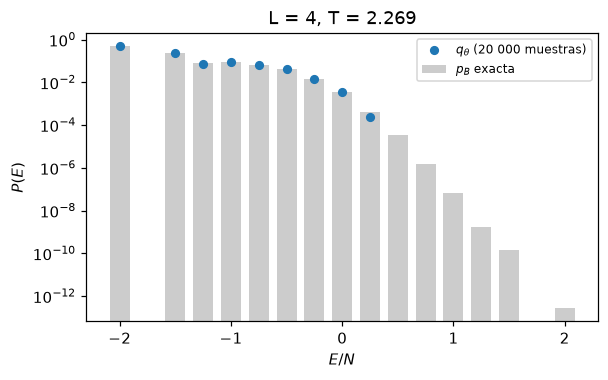

E/N = -2.000: P_B = 4.836e-01, P_q exacta = 4.848e-01, P_q muestras = 4.811e-01
E/N = -1.500: P_B = 2.277e-01, P_q exacta = 2.281e-01, P_q muestras = 2.305e-01
E/N = -1.250: P_B = 7.812e-02, P_q exacta = 7.630e-02, P_q muestras = 7.415e-02
E/N = -1.000: P_B = 8.879e-02, P_q exacta = 8.784e-02, P_q muestras = 8.990e-02
E/N = -0.750: P_B = 6.207e-02, P_q exacta = 6.172e-02, P_q muestras = 6.205e-02
E/N = -0.500: P_B = 4.121e-02, P_q exacta = 4.189e-02, P_q muestras = 4.370e-02
E/N = -0.250: P_B = 1.434e-02, P_q exacta = 1.486e-02, P_q muestras = 1.480e-02
E/N = -0.000: P_B = 3.722e-03, P_q exacta = 3.958e-03, P_q muestras = 3.550e-03
E/N = +0.250: P_B = 4.221e-04, P_q exacta = 4.513e-04, P_q muestras = 2.500e-04
E/N = +0.500: P_B = 3.569e-05, P_q exacta = 3.842e-05, P_q muestras = 0.000e+00
E/N = +0.750: P_B = 1.582e-06, P_q exacta = 1.703e-06, P_q muestras = 0.000e+00
E/N = +1.000: P_B = 6.659e-08, P_q exacta = 6.947e-08, P_q muestras = 0.000e+00
E/N = +1.250: P_B = 1.724e-09, P_q exact

In [11]:
ex = exactos[4]; N = 16
niveles = torch.unique(ex["E"])
PB = np.array([ex["logpB"][ex["E"] == e].exp().sum().item() for e in niveles])
E_lote = energia_ising(eval_lote["L4"]["s"], 4)
Pq = np.array([(E_lote == e).float().mean().item() for e in niveles])
Pq_ex = np.array([eval_ex["L4"]["logq"][ex["E"] == e].exp().sum().item() for e in niveles])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(niveles.numpy() / N, PB, width=0.18, color="0.8", label=r"$p_B$ exacta")
ax.plot(niveles.numpy() / N, Pq, "o", color="C0", ms=5, label=r"$q_\theta$ (20 000 muestras)")
ax.set_yscale("log"); ax.set_xlabel(r"$E/N$"); ax.set_ylabel(r"$P(E)$"); ax.legend(fontsize=8)
ax.set_title(f"L = 4, T = {T0}")
fig.savefig(FIG / "histograma_energias_L4.pdf"); plt.show()
res["histograma_L4"] = dict(E=(niveles.numpy() / N).tolist(), PB=PB.tolist(), Pq_muestras=Pq.tolist(), Pq_exacta=Pq_ex.tolist(),
                            max_dif_rel=float(np.max(np.abs(Pq_ex - PB) / PB)))
for e, a, b, c in zip(niveles.numpy() / N, PB, Pq_ex, Pq):
    print(f"E/N = {e:+.3f}: P_B = {a:.3e}, P_q exacta = {b:.3e}, P_q muestras = {c:.3e}")

### Configuraciones generadas

Primeras ocho configuraciones del lote de evaluación de cada modelo validado, con su magnetización (negro: $s_i=+1$; blanco: $s_i=-1$).

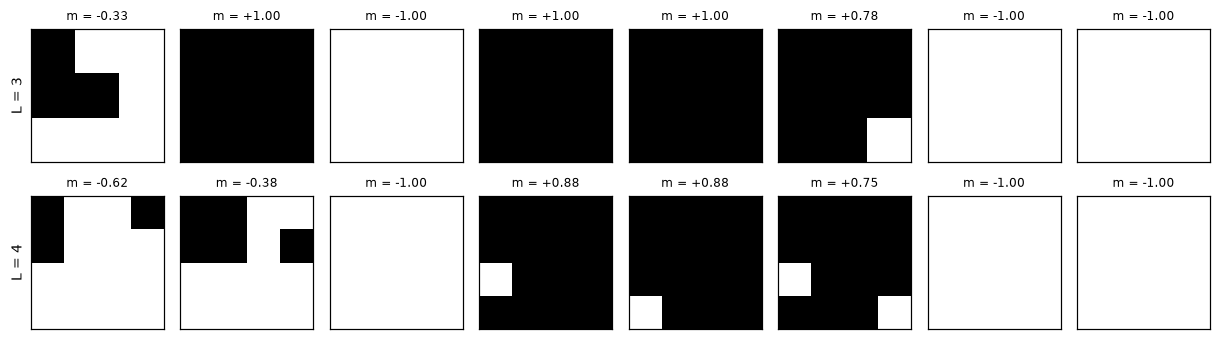

In [12]:
n_ej = 8
fig, ax = plt.subplots(2, n_ej, figsize=(1.4 * n_ej, 3.3))
for fila, clave in enumerate(("L3", "L4")):
    L_ = int(clave[1])
    s_ej = eval_lote[clave]["s"][:n_ej].reshape(-1, L_, L_)
    for j in range(n_ej):
        a = ax[fila, j]
        a.imshow(s_ej[j].numpy(), cmap="gray_r", vmin=-1, vmax=1)
        a.set_xticks([]); a.set_yticks([])
        a.set_title(f"m = {s_ej[j].mean().item():+.2f}", fontsize=8)
    ax[fila, 0].set_ylabel(f"L = {L_}", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "configuraciones_L3_L4.pdf"); plt.show()

## 7. Varianza del estimador del gradiente

Con los parámetros fijos se generan $R=40$ lotes independientes de $M=512$ configuraciones y en cada uno se calcula $\hat g_\theta$ con $b=0$ y con $b=\bar f$. Se reporta la varianza total $\mathrm{tr}\,\mathrm{Cov}(\hat g)=\langle\|\hat g-\langle\hat g\rangle\|^2\rangle$ y la norma del gradiente medio. Se hace para el modelo inicial y para el modelo entrenado de $L=4$.

In [13]:
def varianza_gradiente(modelo, L, T, M=512, R=40, semilla=0):
    torch.manual_seed(semilla)
    g = {False: [], True: []}
    for _ in range(R):
        s, _ = modelo.muestrear(M)
        E = energia_ising(s, L)
        for lb in (False, True):
            l = modelo.log_prob(s)
            f = (E + T * l).detach()
            peso = f - f.mean() if lb else f
            modelo.zero_grad()
            (peso * l).mean().backward()
            g[lb].append(torch.cat([p.grad.flatten() for p in modelo.parameters()]).clone())
    out = {}
    for lb, lista in g.items():
        G = torch.stack(lista)
        media = G.mean(0)
        out["con_b" if lb else "sin_b"] = dict(var_total=((G - media) ** 2).sum(1).mean().item(),
                                                norma_media=media.norm().item())
    return out

torch.manual_seed(0)
res["varianza_gradiente"] = {"inicial": varianza_gradiente(TransformerEspines(16), 4, T0),
                             "entrenado": varianza_gradiente(modelos["L4"], 4, T0)}
for k, v in res["varianza_gradiente"].items():
    print(k, {a: {c: f"{d:.3e}" for c, d in b.items()} for a, b in v.items()},
          f"cociente de varianzas = {v['sin_b']['var_total'] / v['con_b']['var_total']:.0f}")

inicial {'sin_b': {'var_total': '4.131e+02', 'norma_media': '2.005e+01'}, 'con_b': {'var_total': '2.522e+01', 'norma_media': '1.836e+01'}} cociente de varianzas = 16
entrenado {'sin_b': {'var_total': '4.087e+02', 'norma_media': '2.927e+00'}, 'con_b': {'var_total': '8.907e-03', 'norma_media': '7.486e-02'}} cociente de varianzas = 45882


## 8. Dependencia con la temperatura ($L=4$)

Se entrena un modelo independiente para cada temperatura, con los mismos hiperparámetros y $K=1500$, y se compara con la enumeración exacta. También se registra la fracción de muestras con $m>0$ y la probabilidad marginal $q_\theta(s_1=+1)$, que indican si el modelo conserva la simetría $s\to-s$. Por debajo de $T_c$ el modelo pierde esa simetría, y se corrige en la celda siguiente.

In [14]:
temperaturas = [1.0, 1.5, 2.0, 2.269, 2.5, 3.0, 3.5, 4.0]
barrido = []
for T in temperaturas:
    ex = enumeracion_exacta(4, T)
    torch.manual_seed(0)
    m_T = TransformerEspines(16, HP["d"], HP["n_cabezas"], HP["n_capas"])
    h_T = entrenar(m_T, 4, T, M=HP["M"], K=1500, lr=HP["lr"], linea_base=True)
    r = evaluacion_exacta(m_T, ex, T)
    with torch.no_grad():
        p1 = F.softmax(m_T.logits(torch.full((1, 1), BOS)), -1)[0, 0, 1].item()
    torch.manual_seed(123)
    lo = evaluar_lote(m_T, 4, T, M=10000)
    barrido.append(dict(T=T, F=r["F"] / 16, U=r["U"] / 16, m=r["m"], DKL=r["DKL"], FB=ex["FB"] / 16,
                        UB=ex["UB"] / 16, mB=ex["mB"], frac_pos=lo["frac_pos"], q_s1_mas=p1,
                        F_lote=lo["F"], U_lote=lo["U"], m_lote=lo["m"]))
    b_ = barrido[-1]
    print(f"T = {T:5.3f}: F/N = {b_['F']:.5f} (FB/N = {b_['FB']:.5f}), U/N = {b_['U']:.4f} ({b_['UB']:.4f}), "
          f"<|m|> = {b_['m']:.4f} ({b_['mB']:.4f}), D_KL = {b_['DKL']:.2e}, m>0: {b_['frac_pos']:.3f}, "
          f"q(s1=+1) = {p1:.3f}, {h_T['tiempo']:.0f} s")
res["barrido_T_L4"] = [{k: v for k, v in b_.items()} for b_ in barrido]

T = 1.000: F/N = -2.00034 (FB/N = -2.04367), U/N = -1.9972 (-1.9972), <|m|> = 0.9993 (0.9993), D_KL = 6.93e-01, m>0: 0.000, q(s1=+1) = 0.000, 62 s


T = 1.500: F/N = -2.00775 (FB/N = -2.07347), U/N = -1.9561 (-1.9506), <|m|> = 0.9887 (0.9862), D_KL = 7.01e-01, m>0: 0.000, q(s1=+1) = 0.006, 63 s


T = 2.000: F/N = -2.13794 (FB/N = -2.13817), U/N = -1.7631 (-1.7554), <|m|> = 0.9216 (0.9189), D_KL = 1.88e-03, m>0: 0.494, q(s1=+1) = 0.499, 62 s


T = 2.269: F/N = -2.20116 (FB/N = -2.20133), U/N = -1.5677 (-1.5658), <|m|> = 0.8441 (0.8439), D_KL = 1.22e-03, m>0: 0.494, q(s1=+1) = 0.501, 215 s


T = 2.500: F/N = -2.27502 (FB/N = -2.27517), U/N = -1.3839 (-1.3791), <|m|> = 0.7663 (0.7647), D_KL = 9.87e-04, m>0: 0.489, q(s1=+1) = 0.498, 147 s


T = 3.000: F/N = -2.49010 (FB/N = -2.49019), U/N = -1.0169 (-1.0171), <|m|> = 0.6007 (0.6013), D_KL = 4.99e-04, m>0: 0.490, q(s1=+1) = 0.498, 49 s


T = 3.500: F/N = -2.75623 (FB/N = -2.75635), U/N = -0.7775 (-0.7762), <|m|> = 0.4889 (0.4884), D_KL = 5.21e-04, m>0: 0.484, q(s1=+1) = 0.497, 49 s


T = 4.000: F/N = -3.05027 (FB/N = -3.05032), U/N = -0.6277 (-0.6255), <|m|> = 0.4193 (0.4182), D_KL = 1.76e-04, m>0: 0.493, q(s1=+1) = 0.500, 54 s


### Corrección del colapso a baja temperatura

A $T=1.0$ y $1.5$ el modelo queda en un solo sector de magnetización ($m>0$ en ninguna muestra y $q_\theta(s_1=+1)\approx0$), con $D_{KL}\approx\ln2$, y no sale de ahí en las 1500 iteraciones. Por debajo de $T_c$ se repite entonces el entrenamiento con la versión simetrizada, $q_{sym}(s)=\tfrac12[q_\theta(s)+q_\theta(-s)]$, que cubre los dos sectores por construcción y sigue normalizada. Para muestrearla se genera $s\sim q_\theta$ y se invierte toda la configuración con probabilidad $1/2$, y $\ln q_{sym}(s)=\mathrm{logaddexp}(\ln q_\theta(s),\ln q_\theta(-s))-\ln2$. La misma clase se usa en la red $L=8$. Los resultados sin simetrizar quedan en `barrido_T_L4_directo`.

In [7]:
class TransformerZ2(nn.Module):
    # q_sym(s) = [q(s) + q(-s)] / 2, con q un TransformerEspines
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.N = base.N

    def log_prob(self, s):
        return torch.logaddexp(self.base.log_prob(s), self.base.log_prob(-s)) - np.log(2)

    @torch.no_grad()
    def muestrear(self, M, con_logq=True):
        s, _ = self.base.muestrear(M)
        signo = torch.where(torch.rand(M) < 0.5, -1.0, 1.0).to(s.dtype)
        s = s * signo[:, None]
        return s, (self.log_prob(s) if con_logq else None)


barrido_directo = [dict(b_) for b_ in barrido]
for j, T in enumerate(temperaturas):
    if T not in (1.0, 1.5, 2.0):   # T < Tc
        continue
    ex = enumeracion_exacta(4, T)
    torch.manual_seed(0)
    m_T = TransformerZ2(TransformerEspines(16, HP["d"], HP["n_cabezas"], HP["n_capas"]))
    h_T = entrenar(m_T, 4, T, M=HP["M"], K=1500, lr=HP["lr"], linea_base=True)
    r = evaluacion_exacta(m_T, ex, T)
    p1 = r["logq"].exp()[ex["s"][:, 0] > 0].sum().item()   # q(s1=+1), exacta
    torch.manual_seed(123)
    lo = evaluar_lote(m_T, 4, T, M=10000)
    barrido[j] = dict(T=T, F=r["F"] / 16, U=r["U"] / 16, m=r["m"], DKL=r["DKL"], FB=ex["FB"] / 16,
                      UB=ex["UB"] / 16, mB=ex["mB"], frac_pos=lo["frac_pos"], q_s1_mas=p1,
                      F_lote=lo["F"], U_lote=lo["U"], m_lote=lo["m"], simetrizado=True)
    b_ = barrido[j]
    print(f"T = {T:5.3f} (Z2): F/N = {b_['F']:.5f} (FB/N = {b_['FB']:.5f}), U/N = {b_['U']:.4f} ({b_['UB']:.4f}), "
          f"<|m|> = {b_['m']:.4f} ({b_['mB']:.4f}), D_KL = {b_['DKL']:.2e} (antes {barrido_directo[j]['DKL']:.2e}), "
          f"m>0: {b_['frac_pos']:.3f}, q(s1=+1) = {p1:.3f}, {h_T['tiempo']:.0f} s")
res["barrido_T_L4_directo"] = [{k: v for k, v in b_.items()} for b_ in barrido_directo]
res["barrido_T_L4"] = [{k: v for k, v in b_.items()} for b_ in barrido]

T = 1.000 (Z2): F/N = -2.04366 (FB/N = -2.04367), U/N = -1.9973 (-1.9972), <|m|> = 0.9993 (0.9993), D_KL = 1.93e-04 (antes 6.93e-01), m>0: 0.499, q(s1=+1) = 0.500, 136 s


T = 1.500 (Z2): F/N = -2.07274 (FB/N = -2.07347), U/N = -1.9576 (-1.9506), <|m|> = 0.9891 (0.9862), D_KL = 7.84e-03 (antes 7.01e-01), m>0: 0.499, q(s1=+1) = 0.500, 111 s


T = 2.000 (Z2): F/N = -2.13808 (FB/N = -2.13817), U/N = -1.7590 (-1.7554), <|m|> = 0.9203 (0.9189), D_KL = 6.95e-04 (antes 1.88e-03), m>0: 0.501, q(s1=+1) = 0.500, 93 s


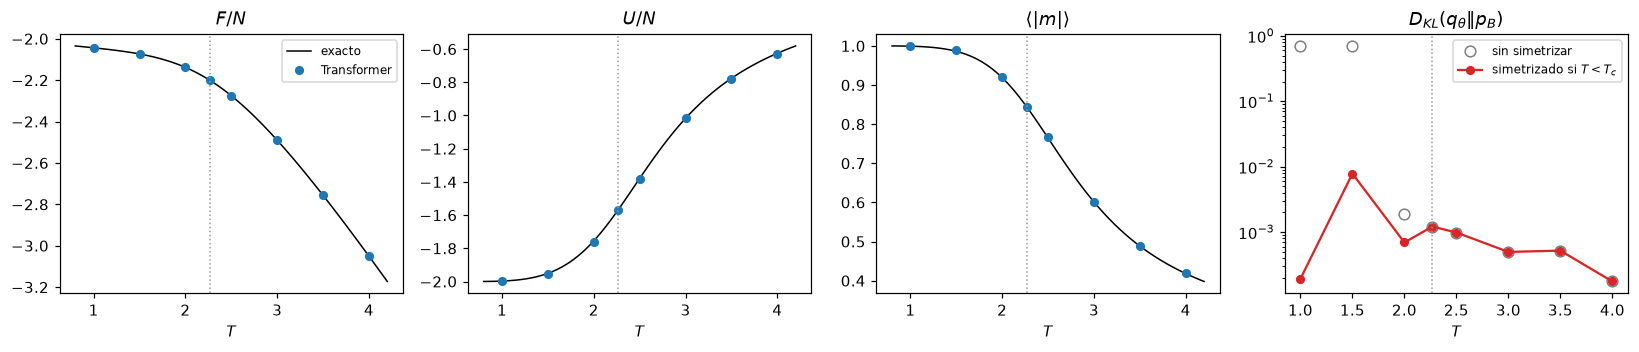

In [8]:
T_fino = np.linspace(0.8, 4.2, 60)
ref = [enumeracion_exacta(4, T) for T in T_fino]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
for a, k, kB, nombre in zip(ax[:3], ("F", "U", "m"), ("FB", "UB", "mB"),
                            (r"$F/N$", r"$U/N$", r"$\langle|m|\rangle$")):
    a.plot(T_fino, [r_[kB] / (16 if kB != "mB" else 1) for r_ in ref], "k-", lw=1, label="exacto")
    a.plot([b_["T"] for b_ in barrido], [b_[k] for b_ in barrido], "o", color="C0", ms=5, label="Transformer")
    a.axvline(TC, color="0.6", ls=":", lw=1)
    a.set_xlabel("$T$"); a.set_title(nombre)
ax[0].legend(fontsize=8)
ax[3].semilogy([b_["T"] for b_ in barrido_directo], [b_["DKL"] for b_ in barrido_directo], "o", mfc="none",
               color="0.5", ms=7, label="sin simetrizar")
ax[3].semilogy([b_["T"] for b_ in barrido], [b_["DKL"] for b_ in barrido], "o-", color="C3", ms=5,
               label="simetrizado si $T<T_c$")
ax[3].axvline(TC, color="0.6", ls=":", lw=1); ax[3].legend(fontsize=8)
ax[3].set_xlabel("$T$"); ax[3].set_title(r"$D_{KL}(q_\theta\|p_B)$")
fig.tight_layout(); fig.savefig(FIG / "observables_vs_T.pdf"); plt.show()

## 9. Red $L=8$

Para $L=8$ ($N=64$) la enumeración ya no es posible. La referencia para $F_B/N$ y $U_B/N$ es la fórmula de Kaufman; para $\langle|m|\rangle$ se usa Metropolis con actualización en tablero de ajedrez (100 cadenas independientes, 2000 barridos de termalización y 5000 de medida, midiendo cada 5 barridos), con el error estimado a partir de la dispersión entre cadenas. Como $F_B$ es exacta, el lote de evaluación da una estimación de $D_{KL}=(\hat F_\theta-F_B)/T$.

Se comparan tres protocolos a $T=1.8$, $2.269$ y $3.0$, con $K=1000$ iteraciones y los mismos hiperparámetros:

1. *directo*: el algoritmo de la sección 5 con línea base, a temperatura fija;
2. *recocido* (solo $T=1.8$): $\beta$ crece linealmente desde $\beta/500$ hasta $\beta$ en las primeras 500 de las 1000 iteraciones;
3. *Z2*: el modelo se simetriza, $q_{sym}(s)=\tfrac12[q_\theta(s)+q_\theta(-s)]$, con el mismo Transformer adentro.

La versión simetrizada es la de la sección 8. Cada evaluación cuesta dos pasadas.

Como el modelo da $\ln q(s)$, también se puede estimar $Z$ por muestreo de importancia, $Z=\langle e^{-f/T}\rangle_{q}$, y con ello $F_B$ sin usar la fórmula exacta. Se reporta además el tamaño efectivo de muestra relativo, $(\sum w)^2/(M\sum w^2)$ con $w=e^{-f/T}$.

In [16]:
# TransformerZ2 se define en la sección 8.

def metropolis(L, T, n_cadenas=100, n_term=2000, n_med=5000, cada=5, semilla=0):
    rng = np.random.default_rng(semilla)
    s = rng.choice([-1, 1], size=(n_cadenas, L, L))
    x, y = np.indices((L, L))
    color = (x + y) % 2
    E_med, m_med = [], []
    for t in range(n_term + n_med):
        for c in (0, 1):
            vec = np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2)
            acepta = (color == c) & (rng.random(s.shape) < np.exp(-2 * s * vec / T))
            s = np.where(acepta, -s, s)
        if t >= n_term and (t - n_term) % cada == 0:
            E = -(s * (np.roll(s, -1, 1) + np.roll(s, -1, 2))).sum(axis=(1, 2))
            E_med.append(E / L**2); m_med.append(np.abs(s.mean(axis=(1, 2))))
    ee = lambda a: (float(a.mean()), float(a.mean(0).std(ddof=1) / np.sqrt(a.shape[1])))
    return dict(U=ee(np.array(E_med)), m=ee(np.array(m_med)))


# prueba de la version simetrizada con L = 3: normalizacion y simetria exactas
torch.manual_seed(0)
mz = TransformerZ2(TransformerEspines(9))
ex3 = enumeracion_exacta(3, 2.269)
r3 = evaluacion_exacta(mz, ex3, 2.269)
with torch.no_grad():
    asim = (mz.log_prob(ex3["s"].float()) - mz.log_prob(-ex3["s"].float())).abs().max().item()
print(f"Z2, L=3: |sum q - 1| = {abs(r3['norma'] - 1):.1e}, max |ln q(s) - ln q(-s)| = {asim:.1e}")

Z2, L=3: |sum q - 1| = 0.0e+00, max |ln q(s) - ln q(-s)| = 0.0e+00


In [17]:
T_L8 = [1.8, 2.269, 3.0]
K_L8 = 1000
corridas = [("directo", T, {}) for T in T_L8] + [("recocido", 1.8, {"K_rec": 500})] \
         + [("Z2", T, {}) for T in T_L8]
ref_L8 = {T: dict(FB=-T * logZ_kaufman(8, T) / 64, UB=U_kaufman(8, T) / 64, mc=metropolis(8, T)) for T in T_L8}
res["L8_referencia"] = {T: dict(FB=r_["FB"], UB=r_["UB"], U_mc=r_["mc"]["U"], m_mc=r_["mc"]["m"])
                        for T, r_ in ref_L8.items()}
for T, r_ in ref_L8.items():
    print(f"T = {T}: FB/N = {r_['FB']:.5f}, U/N Kaufman = {r_['UB']:.4f}, "
          f"Metropolis U/N = {r_['mc']['U'][0]:.4f} ± {r_['mc']['U'][1]:.4f}, <|m|> = {r_['mc']['m'][0]:.4f} ± {r_['mc']['m'][1]:.4f}")

res["L8"], hist_L8, lotes_L8 = {}, {}, {}
for tipo, T, extra in corridas:
    clave = f"{tipo}_T{T}"
    torch.manual_seed(0)
    base = TransformerEspines(64, HP["d"], HP["n_cabezas"], HP["n_capas"])
    m8 = TransformerZ2(base) if tipo == "Z2" else base
    hist_L8[clave] = entrenar(m8, 8, T, M=HP["M"], K=K_L8, lr=HP["lr"], linea_base=True, **extra)
    torch.manual_seed(123)
    lo = evaluar_lote(m8, 8, T, M=20000)
    lotes_L8[clave] = lo
    FB = ref_L8[T]["FB"]
    res["L8"][clave] = dict(T=T, tipo=tipo, F_lote=lo["F"], U_lote=lo["U"], S_lote=lo["S"], m_lote=lo["m"],
                            frac_pos=lo["frac_pos"], DKL_est=(lo["F"][0] - FB) * 64 / T,
                            DKL_err=lo["F"][1] * 64 / T, FB_is=lo["FB_is"], ess=lo["ess"],
                            tiempo=hist_L8[clave]["tiempo"])
    v = res["L8"][clave]
    print(f"{clave:13s}: F/N = {v['F_lote'][0]:.5f} ± {v['F_lote'][1]:.5f} (FB/N = {FB:.5f}), "
          f"D_KL ≈ {v['DKL_est']:.3f} ± {v['DKL_err']:.3f}, U/N = {v['U_lote'][0]:.4f}, "
          f"<|m|> = {v['m_lote'][0]:.4f}, m>0: {v['frac_pos']:.3f}, FB/N imp. = {v['FB_is']:.5f}, "
          f"ESS/M = {v['ess']:.3f}, {v['tiempo']:.0f} s")

T = 1.8: FB/N = -2.04684, U/N Kaufman = -1.8592, Metropolis U/N = -1.8585 ± 0.0004, <|m|> = 0.9565 ± 0.0002
T = 2.269: FB/N = -2.13234, U/N Kaufman = -1.4918, Metropolis U/N = -1.4899 ± 0.0011, <|m|> = 0.7755 ± 0.0008
T = 3.0: FB/N = -2.44975, U/N Kaufman = -0.8413, Metropolis U/N = -0.8431 ± 0.0009, <|m|> = 0.3469 ± 0.0008


directo_T1.8 : F/N = -2.02362 ± 0.00006 (FB/N = -2.04684), D_KL ≈ 0.826 ± 0.002, U/N = -1.8899, <|m|> = 0.9709, m>0: 0.000, FB/N imp. = -2.02632, ESS/M = 0.311, 243 s


directo_T2.269: F/N = -2.09165 ± 0.00016 (FB/N = -2.13234), D_KL ≈ 1.147 ± 0.004, U/N = -1.6306, <|m|> = 0.8819, m>0: 0.000, FB/N imp. = -2.10975, ESS/M = 0.012, 244 s


directo_T3.0 : F/N = -2.44550 ± 0.00014 (FB/N = -2.44975), D_KL ≈ 0.091 ± 0.003, U/N = -0.8350, <|m|> = 0.3486, m>0: 0.507, FB/N imp. = -2.44980, ESS/M = 0.825, 244 s


recocido_T1.8: F/N = -2.02291 ± 0.00007 (FB/N = -2.04684), D_KL ≈ 0.851 ± 0.003, U/N = -1.8890, <|m|> = 0.9711, m>0: 1.000, FB/N imp. = -2.02663, ESS/M = 0.158, 249 s


Z2_T1.8      : F/N = -2.04317 ± 0.00006 (FB/N = -2.04684), D_KL ≈ 0.130 ± 0.002, U/N = -1.8923, <|m|> = 0.9716, m>0: 0.505, FB/N imp. = -2.04587, ESS/M = 0.300, 399 s


Z2_T2.269    : F/N = -2.11600 ± 0.00015 (FB/N = -2.13234), D_KL ≈ 0.461 ± 0.004, U/N = -1.6366, <|m|> = 0.8861, m>0: 0.505, FB/N imp. = -2.13027, ESS/M = 0.027, 450 s


Z2_T3.0      : F/N = -2.44708 ± 0.00011 (FB/N = -2.44975), D_KL ≈ 0.057 ± 0.002, U/N = -0.8291, <|m|> = 0.3450, m>0: 0.507, FB/N imp. = -2.44981, ESS/M = 0.890, 468 s


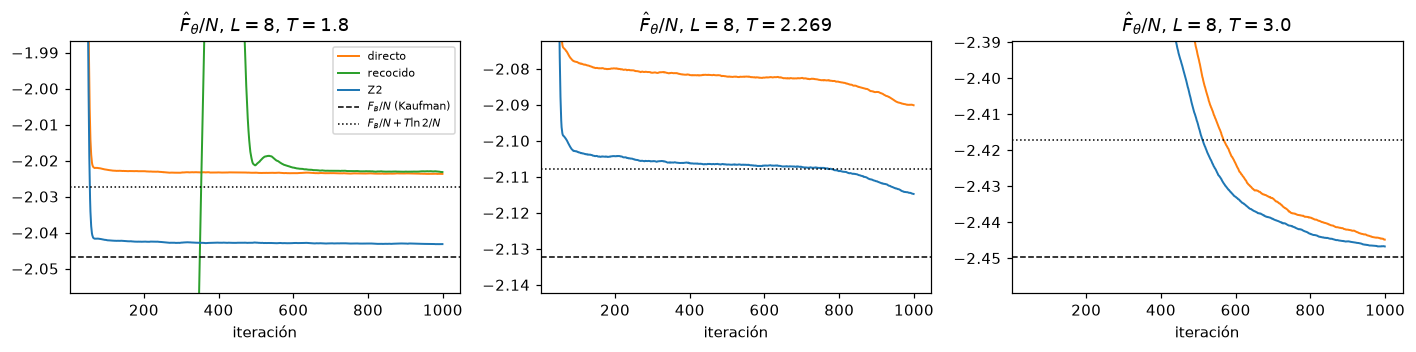

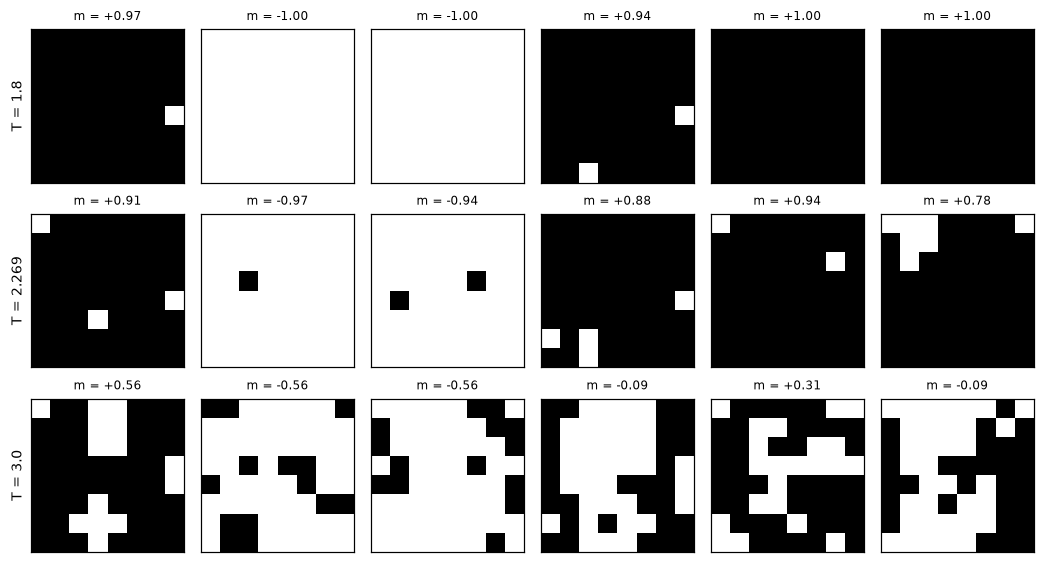

In [18]:
fig, ax = plt.subplots(1, len(T_L8), figsize=(13, 3.3))
for a, T in zip(ax, T_L8):
    FB = ref_L8[T]["FB"]
    for tipo, color in (("directo", "C1"), ("recocido", "C2"), ("Z2", "C0")):
        clave = f"{tipo}_T{T}"
        if clave not in hist_L8:
            continue
        F8 = hist_L8[clave]["F"] / 64
        a.plot(np.arange(49, len(F8)), media_movil(F8), color=color, lw=1.3, label=tipo)
    a.axhline(FB, color="k", ls="--", lw=1, label=r"$F_B/N$ (Kaufman)")
    a.axhline(FB + T * np.log(2) / 64, color="k", ls=":", lw=1, label=r"$F_B/N+T\ln 2/N$")
    a.set_ylim(FB - 0.01, FB + 0.06)
    a.set_xlabel("iteración"); a.set_title(rf"$\hat F_\theta/N$, $L=8$, $T={T}$")
ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "curvas_L8.pdf"); plt.show()

n_ej = 6
fig, ax = plt.subplots(len(T_L8), n_ej, figsize=(1.6 * n_ej, 1.75 * len(T_L8)))
for fila, T in enumerate(T_L8):
    s8 = lotes_L8[f"Z2_T{T}"]["s"][:n_ej].reshape(-1, 8, 8)
    for j in range(n_ej):
        a = ax[fila, j]
        a.imshow(s8[j].numpy(), cmap="gray_r", vmin=-1, vmax=1)
        a.set_xticks([]); a.set_yticks([])
        a.set_title(f"m = {s8[j].mean().item():+.2f}", fontsize=8)
    ax[fila, 0].set_ylabel(f"T = {T}", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "configuraciones.pdf"); plt.show()

## 10. Resultados guardados

In [19]:
def a_json(o):
    if isinstance(o, dict):
        return {str(k): a_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [a_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

res["tiempo_total_min"] = (time.time() - t_inicio) / 60
with open(FIG / "resultados.json", "w") as fh:
    json.dump(a_json(res), fh, indent=1)
print(f"tiempo total: {res['tiempo_total_min']:.1f} min")

tiempo total: 66.2 min
